In [25]:
!pip install facenet-pytorch==2.5.3 -q

In [26]:
import torch
import numpy as np
from PIL import Image
from facenet_pytorch import MTCNN, InceptionResnetV1
import os
from sklearn.metrics import roc_auc_score, accuracy_score,roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm


In [27]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

mtcnn = MTCNN(
    image_size=160,
    margin=20,
    keep_all=False,
    device=device
)

facenet = InceptionResnetV1(pretrained='vggface2').eval().to(device)
print("Models loaded successfully")

Using device: cuda
Models loaded successfully


In [49]:
def get_embedding(image_path):
    img = Image.open(image_path).convert('RGB')
    img_array = np.array(img, dtype=np.uint8)
    img = Image.fromarray(img_array)
    
    face_tensor = mtcnn(img)
    
    if face_tensor is None:
        print("No face detected in:", image_path)
        return None
    
    face_tensor = face_tensor.unsqueeze(0).to(device)
    
    with torch.no_grad():
        embedding = facenet(face_tensor)
    
    return embedding.cpu().numpy()


def verify_faces(path1, path2, threshold=1.03):
    emb1 = get_embedding(path1)
    emb2 = get_embedding(path2)
    
    if emb1 is None or emb2 is None:
        return None
    
    distance = np.linalg.norm(emb1 - emb2)
    verified = distance < threshold
    confidence = round((1 - distance / 2) * 100, 2)
    
    print(f"Distance:   {distance:.4f}")
    print(f"Threshold:  {threshold}")
    print(f"Confidence: {confidence}%")
    print(f"Result:     {'Same person' if verified else 'Different person'}")
    
    return verified, distance, confidence

In [50]:
base_path = '/kaggle/input/datasets/jonathanloscalzo/lfw-cropped-faces/lfw_cut/'

def get_image_path(name, num, base_path):
    return os.path.join(base_path, f"{name}/{name}_{str(num).zfill(4)}.jpg")

path1 = get_image_path("Abdullah", 1, base_path)
path2 = get_image_path("Abdullah", 2, base_path)
path3 = get_image_path("Colin_Powell", 1, base_path)

print("=== Same Person ===")
verify_faces(path1, path2)

print()

print("=== Different Person ===")
verify_faces(path1, path3)

=== Same Person ===
Distance:   0.6820
Threshold:  1.03
Confidence: 65.9000015258789%
Result:     Same person

=== Different Person ===
Distance:   1.5563
Threshold:  1.03
Confidence: 22.190000534057617%
Result:     Different person


(np.False_, np.float32(1.5562642), np.float32(22.19))

In [30]:
for root, dirs, files in os.walk('/kaggle/input/'):
    for f in files:
        if 'matchpairs' in f.lower():
            print(os.path.join(root, f))

/kaggle/input/datasets/jessicali9530/lfw-dataset/mismatchpairsDevTrain.csv
/kaggle/input/datasets/jessicali9530/lfw-dataset/matchpairsDevTest.csv
/kaggle/input/datasets/jessicali9530/lfw-dataset/mismatchpairsDevTest.csv
/kaggle/input/datasets/jessicali9530/lfw-dataset/matchpairsDevTrain.csv


In [31]:
y_true = []
y_scores = []

print("Evaluating same person pairs...")
skipped = 0
for _, row in tqdm(match_test.iterrows(), total=len(match_test)):
    path1 = get_image_path(row['name'], row['imagenum1'], base_path)
    path2 = get_image_path(row['name'], row['imagenum2'], base_path)
    
    if not os.path.exists(path1) or not os.path.exists(path2):
        skipped += 1
        continue
        
    emb1 = get_embedding(path1)
    emb2 = get_embedding(path2)
    if emb1 is not None and emb2 is not None:
        dist = np.linalg.norm(emb1 - emb2)
        y_true.append(1)
        y_scores.append(-dist)

print(f"Skipped {skipped} missing pairs")


print("\nEvaluating different person pairs...")
skipped = 0
for _, row in tqdm(mismatch_test.iterrows(), total=len(mismatch_test)):
    path1 = get_image_path(row['name'], row['imagenum1'], base_path)
    path2 = get_image_path(row['name.1'], row['imagenum2'], base_path)
    
    if not os.path.exists(path1) or not os.path.exists(path2):
        skipped += 1
        continue
        
    emb1 = get_embedding(path1)
    emb2 = get_embedding(path2)
    if emb1 is not None and emb2 is not None:
        dist = np.linalg.norm(emb1 - emb2)
        y_true.append(0)
        y_scores.append(-dist)

print(f"Skipped {skipped} missing pairs")
print(f"\nTotal pairs evaluated: {len(y_true)}")

Evaluating same person pairs...


  1%|          | 3/500 [00:00<00:26, 18.94it/s]

No face detected in: /kaggle/input/datasets/jonathanloscalzo/lfw-cropped-faces/lfw_cut/Abdullah_Gul/Abdullah_Gul_0013.jpg
No face detected in: /kaggle/input/datasets/jonathanloscalzo/lfw-cropped-faces/lfw_cut/Abdullah_Gul/Abdullah_Gul_0013.jpg


  1%|▏         | 7/500 [00:00<00:30, 16.09it/s]

No face detected in: /kaggle/input/datasets/jonathanloscalzo/lfw-cropped-faces/lfw_cut/Alan_Greenspan/Alan_Greenspan_0001.jpg


...

No face detected in: /kaggle/input/datasets/jonathanloscalzo/lfw-cropped-faces/lfw_cut/William_Martin/William_Martin_0001.jpg


 97%|█████████▋| 487/500 [00:33<00:00, 14.85it/s]

No face detected in: /kaggle/input/datasets/jonathanloscalzo/lfw-cropped-faces/lfw_cut/Sarah_Canale/Sarah_Canale_0001.jpg


100%|██████████| 500/500 [00:34<00:00, 14.60it/s]

Skipped 6 missing pairs

Total pairs evaluated: 859


In [32]:
thresholds = np.arange(0.5, 1.5, 0.01)
best_acc = 0
best_threshold = 0

for threshold in thresholds:
    preds = [1 if -s < threshold else 0 for s in y_scores]
    acc = accuracy_score(y_true, preds)
    if acc > best_acc:
        best_acc = acc
        best_threshold = threshold

print(f"Best threshold: {best_threshold:.2f}")
print(f"Best accuracy:  {best_acc * 100:.2f}%")
print(f"AUC:            {roc_auc_score(y_true, y_scores):.4f}")

Best threshold: 1.03
Best accuracy:  98.60%
AUC:            0.9957


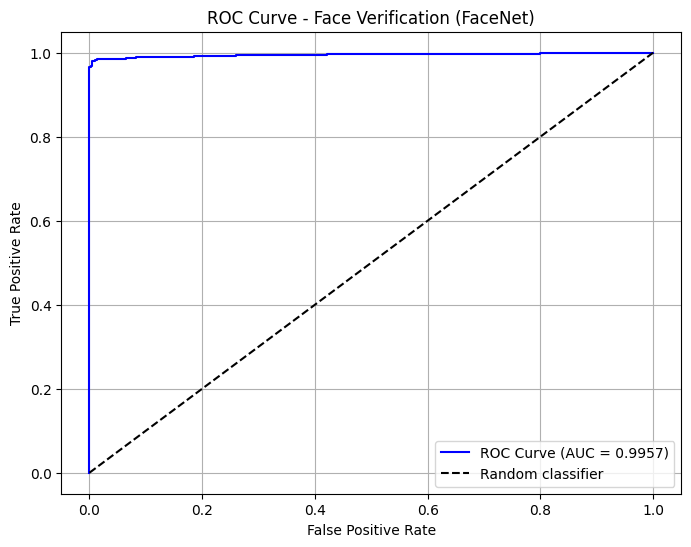

Final Results:
Accuracy:  98.60%
AUC:       0.9957
Threshold: 1.03


In [33]:


# ROC curve
fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Face Verification (FaceNet)')
plt.legend()
plt.grid(True)
plt.show()

print(f"Final Results:")
print(f"Accuracy:  98.60%")
print(f"AUC:       {roc_auc:.4f}")
print(f"Threshold: 1.03")

**Anti Spoofing detection**

In [43]:
!git clone https://github.com/minivision-ai/Silent-Face-Anti-Spoofing.git -q

In [44]:
import os
os.chdir('Silent-Face-Anti-Spoofing')
print("Current directory:", os.getcwd())
print("Files:", os.listdir('.'))

Current directory: /kaggle/working/Silent-Face-Anti-Spoofing/Silent-Face-Anti-Spoofing
Files: ['README_EN.md', 'resources', 'test.py', 'requirements.txt', 'saved_logs', 'train.py', '.gitignore', 'images', 'README.md', 'src', 'LICENSE', 'datasets', '.git']


In [45]:
from src.anti_spoof_predict import AntiSpoofPredict
from src.generate_patches import CropImage

model_dir = 'resources/anti_spoof_models'
model_test = AntiSpoofPredict(0)
image_cropper = CropImage()

print("Anti-spoofing model loaded successfully")
print("Models available:", os.listdir(model_dir))

Anti-spoofing model loaded successfully
Models available: ['4_0_0_80x80_MiniFASNetV1SE.pth', '2.7_80x80_MiniFASNetV2.pth']


In [51]:
from src.utility import parse_model_name

def check_spoofing(image_path):
    img = cv2.imread(image_path)
    
    if img is None:
        print("Could not read image:", image_path)
        return None
    
    image_bbox = model_test.get_bbox(img)
    
    prediction = np.zeros((1, 3))
    
    for model_name in os.listdir(model_dir):
        h_input, w_input, model_type, scale = parse_model_name(model_name)
        param = {
            "org_img": img,
            "bbox": image_bbox,
            "scale": scale,
            "out_w": w_input,
            "out_h": h_input,
            "crop": True,
        }
        if scale is None:
            param["crop"] = False
        img_patch = image_cropper.crop(**param)
        prediction += model_test.predict(img_patch, os.path.join(model_dir, model_name))

    # get result
    label = np.argmax(prediction)
    score = prediction[0][label] / 2

    if label == 1:
        print(f" Real face detected  (confidence: {score:.2f})")
        return True
    else:
        print(f" Spoof detected — fake face (confidence: {score:.2f})")
        return False

Abvious Result From LFW because The data is about photos and Anti Spoofing Detects photos 
u can test it with Webcam on local host with a person holding a photo 

In [52]:
test_image = '/kaggle/input/datasets/jonathanloscalzo/lfw-cropped-faces/lfw_cut/Abid_Hamid_Mahmud_Al-Tikriti/Abid_Hamid_Mahmud_Al-Tikriti_0001.jpg'
check_spoofing(test_image)

 Spoof detected — fake face (confidence: 1.00)


False